# Learning Rate Schedule

**Idea:** compare a constant learning rate with one that is cut in half every 2 epochs (StepLR).


In [7]:
import os, time, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

# Fix the random seed so results are repeatable
torch.manual_seed(42)
np.random.seed(42)

# Folders for the dataset and for saved results
from google.colab import drive
drive.mount("/content/drive")
os.chdir("/content/drive/MyDrive")  # data/ and outputs/ will now be created here
os.makedirs("data", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

print("PyTorch version:", torch.__version__)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PyTorch version: 2.11.0+cpu


In [8]:
# Fashion-MNIST: 28x28 grayscale pictures of clothes, 10 classes
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.286,), (0.353,))])
full_train = datasets.FashionMNIST("data", train=True, download=True, transform=transform)
test_data = datasets.FashionMNIST("data", train=False, download=True, transform=transform)

# Shuffle once, then use 12,000 images for training and 3,000 for validation
idx = np.random.permutation(len(full_train))
train_data = Subset(full_train, idx[:12000].tolist())
val_data = Subset(full_train, idx[12000:15000].tolist())

train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
val_loader = DataLoader(val_data, batch_size=64)
test_loader = DataLoader(test_data, batch_size=64)
print("train / val / test sizes:", len(train_data), len(val_data), len(test_data))

train / val / test sizes: 12000 3000 10000


In [9]:
# A simple neural network: 784 pixels -> 256 -> 128 -> 10 classes
class MLP(nn.Module):
    def __init__(self, dropout=0.0):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(256, 128), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.layers(x)

In [10]:
loss_fn = nn.CrossEntropyLoss()

def evaluate(model, loader):
    """Return (average loss, accuracy) of the model on a dataset."""
    model.eval()
    correct, total, loss_sum = 0, 0, 0.0
    with torch.no_grad():
        for x, y in loader:
            out = model(x)
            loss_sum += loss_fn(out, y).item() * len(y)
            correct += (out.argmax(1) == y).sum().item()
            total += len(y)
    return loss_sum / total, correct / total

def train(model, loader, epochs=3, lr=1e-3, weight_decay=0.0, make_scheduler=None):
    """Train with Adam. Returns a table of per-epoch results and the training time."""
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = make_scheduler(optimizer) if make_scheduler else None
    history = []
    start = time.time()
    for epoch in range(epochs):
        model.train()
        loss_sum, seen = 0.0, 0
        for x, y in loader:
            optimizer.zero_grad()
            loss = loss_fn(model(x), y)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * len(y)
            seen += len(y)
        val_loss, val_acc = evaluate(model, val_loader)
        history.append({"epoch": epoch + 1, "train_loss": loss_sum / seen, "val_loss": val_loss,
                        "val_acc": val_acc, "lr": optimizer.param_groups[0]["lr"]})
        print(f"epoch {epoch+1}/{epochs}  train_loss={loss_sum/seen:.4f}  val_loss={val_loss:.4f}  val_acc={val_acc:.4f}")
        if scheduler:
            scheduler.step()
    return pd.DataFrame(history), time.time() - start

## Train with both settings (4 epochs each)

In [11]:
rows = []
histories = {}

# None means "no scheduler" (constant learning rate)
settings = [("constant", None),
            ("StepLR", lambda opt: torch.optim.lr_scheduler.StepLR(opt, step_size=2, gamma=0.5))]

for name, make_scheduler in settings:
    print("---", name)
    torch.manual_seed(42)
    model = MLP()
    hist, secs = train(model, train_loader, epochs=4, make_scheduler=make_scheduler)
    histories[name] = hist
    test_loss, test_acc = evaluate(model, test_loader)
    rows.append({"condition": name, "test_accuracy": test_acc, "test_loss": test_loss, "training_seconds": secs})

results = pd.DataFrame(rows)
results.to_csv("outputs/learning_rate_results.csv", index=False)
print(results)

--- constant
epoch 1/4  train_loss=0.6612  val_loss=0.4516  val_acc=0.8360
epoch 2/4  train_loss=0.4411  val_loss=0.4100  val_acc=0.8507
epoch 3/4  train_loss=0.3853  val_loss=0.3901  val_acc=0.8580
epoch 4/4  train_loss=0.3443  val_loss=0.3927  val_acc=0.8653
--- StepLR
epoch 1/4  train_loss=0.6612  val_loss=0.4516  val_acc=0.8360
epoch 2/4  train_loss=0.4411  val_loss=0.4100  val_acc=0.8507
epoch 3/4  train_loss=0.3581  val_loss=0.3720  val_acc=0.8637
epoch 4/4  train_loss=0.3324  val_loss=0.3768  val_acc=0.8660
  condition  test_accuracy  test_loss  training_seconds
0  constant         0.8403   0.439023         12.014547
1    StepLR         0.8416   0.422568         12.051690


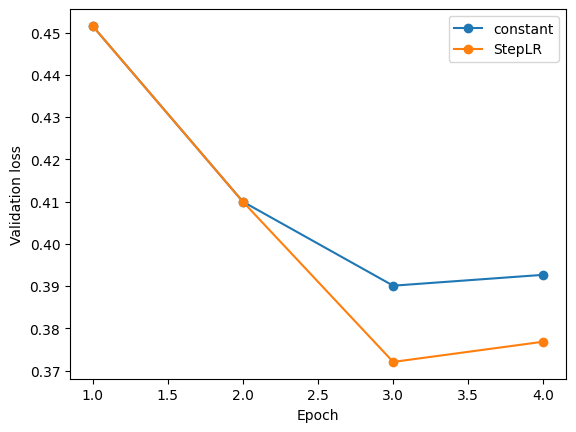

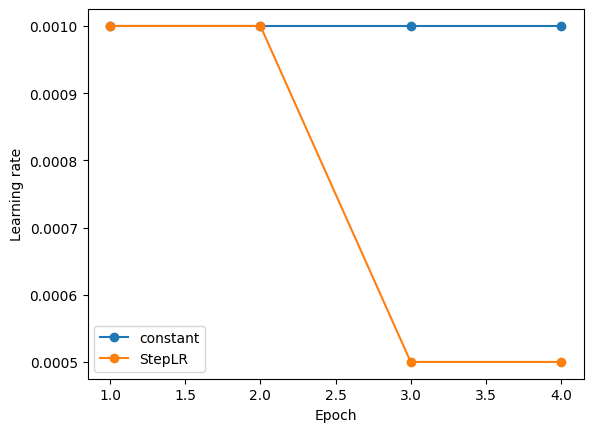

In [12]:
for name, h in histories.items():
    plt.plot(h["epoch"], h["val_loss"], marker="o", label=name)
plt.xlabel("Epoch")
plt.ylabel("Validation loss")
plt.legend()
plt.savefig("outputs/validation_loss.png", dpi=150, bbox_inches="tight")
plt.show()

for name, h in histories.items():
    plt.plot(h["epoch"], h["lr"], marker="o", label=name)
plt.xlabel("Epoch")
plt.ylabel("Learning rate")
plt.legend()
plt.savefig("outputs/learning_rate.png", dpi=150, bbox_inches="tight")
plt.show()